Naman Mehta Code for Assignment 2- Trading and Portfolio Management

1. Installing and importing relevant packages

In [1]:
# Installing Libraries not available in Google Colab
!pip install pandas-ta
!pip install --upgrade pandas
!pip install mplfinance
!pip install vectorbt
!pip uninstall numpy -y
!pip install numpy==1.25.2
!pip install yfinance --upgrade --no-cache-dir


     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 60.9/60.9 kB 4.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 19.5/19.5 MB 58.0 MB/s eta 0:00:00
  Attempting uninstall: numpy
    Found existing installation: numpy 2.2.4
    Uninstalling numpy-2.2.4:
      Successfully uninstalled numpy-2.2.4
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires pandas==2.2.2, but you have pandas 2.2.3 which is incompatible.
Found existing installation: numpy 2.0.2
Uninstalling numpy-2.0.2:
  Successfully uninstalled numpy-2.0.2
  Using cached numpy-1.25.2-cp311-cp311-manylinux_2_17_x86_64.manylinux2014_x86_64.whl.metadata (5.6 kB)
Using cached numpy-1.25.2-cp311-cp311-manylinux_2_17_x86_64.manylinux2014_x86_64.whl (18.2 MB)
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviou

In [1]:
# Uninstalling the old version and downloading the latest version of numpy
!pip uninstall numpy -y
!pip install numpy==1.25.2


Found existing installation: numpy 1.25.2
Uninstalling numpy-1.25.2:
  Successfully uninstalled numpy-1.25.2
  Using cached numpy-1.25.2-cp311-cp311-manylinux_2_17_x86_64.manylinux2014_x86_64.whl.metadata (5.6 kB)
Using cached numpy-1.25.2-cp311-cp311-manylinux_2_17_x86_64.manylinux2014_x86_64.whl (18.2 MB)
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires pandas==2.2.2, but you have pandas 2.2.3 which is incompatible.
blosc2 3.2.0 requires numpy>=1.26, but you have numpy 1.25.2 which is incompatible.
tensorflow 2.18.0 requires numpy<2.1.0,>=1.26.0, but you have numpy 1.25.2 which is incompatible.


In [2]:
# Import package dependencies
import pandas as pd  # for dealing with data
import numpy as np  # for dealing with data
import yfinance as yf  # for downloading financial data
import pandas_ta as ta # for technical analysis using pandas
import mplfinance as mpf #for plotting candle-stick charts
import matplotlib.pyplot as plt
from termcolor import colored as cl
import seaborn as sns  # for making plots look nicer
import vectorbt as vbt
import math as math
sns.set()  # implementing Seaborn's style and themes
plt.style.use("Solarize_Light2")
pd.options.display.float_format = '{:.4f}'.format
plt.rcParams['figure.figsize'] = (20,10)

2. Market Outlook and Technical Indicator Analysis: 9-day and 21-day EMA, RSI and Bollinger Bands

In [17]:
# Downloading Nifty-50 1 year data from yFinance
ticker = "^NSEI"
start_date= "2024-01-01"
end_date = "2025-03-29"
nifty = yf.download(ticker, start=start_date, end=end_date, auto_adjust = False, multi_level_index=False)
nifty

[*********************100%***********************]  1 of 1 completed


,Adj Close,Close,High,Low,Open,Volume
Date,,,,,,
2024-01-01,21741.9004,21741.9004,21834.3496,21680.8496,21727.7500,154000
2024-01-02,21665.8008,21665.8008,21755.5996,21555.6504,21751.3496,263700
2024-01-03,21517.3496,21517.3496,21677.0000,21500.3496,21661.0996,311900
2024-01-04,21658.5996,21658.5996,21685.6504,21564.5508,21605.8008,339200
2024-01-05,21710.8008,21710.8008,21749.5996,21629.1992,21705.7500,309300
...,...,...,...,...,...,...
2025-03-24,23658.3496,23658.3496,23708.7500,23433.5000,23515.4004,311900
2025-03-25,23668.6504,23668.6504,23869.5996,23601.4004,23751.5000,338200
2025-03-26,23486.8496,23486.8496,23736.5000,23451.6992,23700.9492,278600


In [4]:
# Calculate the 21-day and 9-day Exponential Moving Averages (EMA)
nifty["EMA_21"] = ta.ema(nifty["Close"], length=21)
nifty["EMA_9"] = ta.ema(nifty["Close"], length=9)
nifty

,Adj Close,Close,High,Low,Open,Volume,EMA_21,EMA_9
Date,,,,,,,,
2024-01-01,21741.9004,21741.9004,21834.3496,21680.8496,21727.7500,154000,NaN,NaN
2024-01-02,21665.8008,21665.8008,21755.5996,21555.6504,21751.3496,263700,NaN,NaN
2024-01-03,21517.3496,21517.3496,21677.0000,21500.3496,21661.0996,311900,NaN,NaN
2024-01-04,21658.5996,21658.5996,21685.6504,21564.5508,21605.8008,339200,NaN,NaN
2024-01-05,21710.8008,21710.8008,21749.5996,21629.1992,21705.7500,309300,NaN,NaN
...,...,...,...,...,...,...,...,...
2025-03-24,23658.3496,23658.3496,23708.7500,23433.5000,23515.4004,311900,22847.2363,23014.8774
2025-03-25,23668.6504,23668.6504,23869.5996,23601.4004,23751.5000,338200,22921.9103,23145.6320
2025-03-26,23486.8496,23486.8496,23736.5000,23451.6992,23700.9492,278600,22973.2685,23213.8755


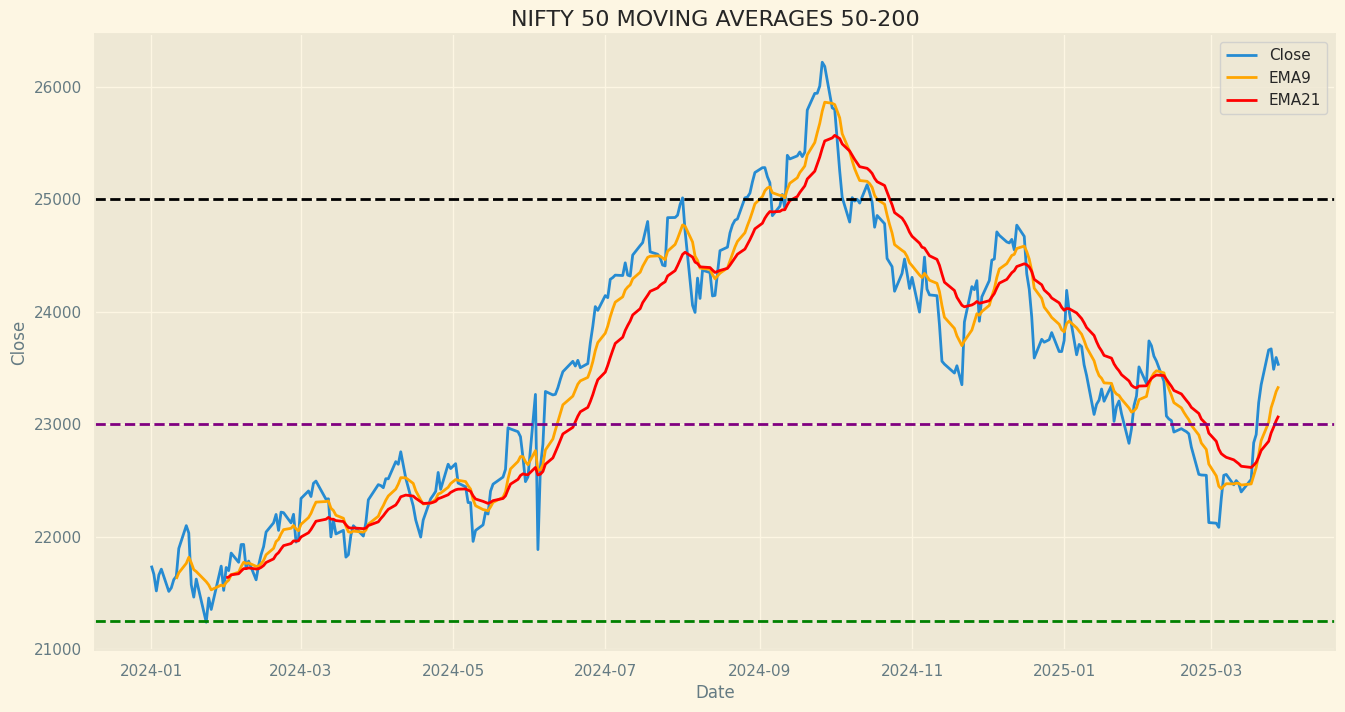

In [5]:
# Plotting EMA
plt.figure(figsize=(16, 8))
plt.plot(nifty['Close'], label = 'Close') # Accessing the 'Close' column from the dataframe
plt.plot(nifty['EMA_9'], color = 'orange', label = 'EMA9') # Accessing the EMA_9 column
plt.plot(nifty['EMA_21'], color = 'red', label = 'EMA21') # Accessing the EMA_21 column
plt.legend()
plt.title('NIFTY 50 MOVING AVERAGES 50-200')
plt.xlabel('Date')
plt.ylabel('Close')

# Creating relevant support and resistance levels
plt.axhline(y=21250, color='green', linestyle='--', label='21250')
plt.axhline(y=23000, color='purple', linestyle='--', label='23000')
plt.axhline(y=25000, color='black', linestyle='--', label='25000')


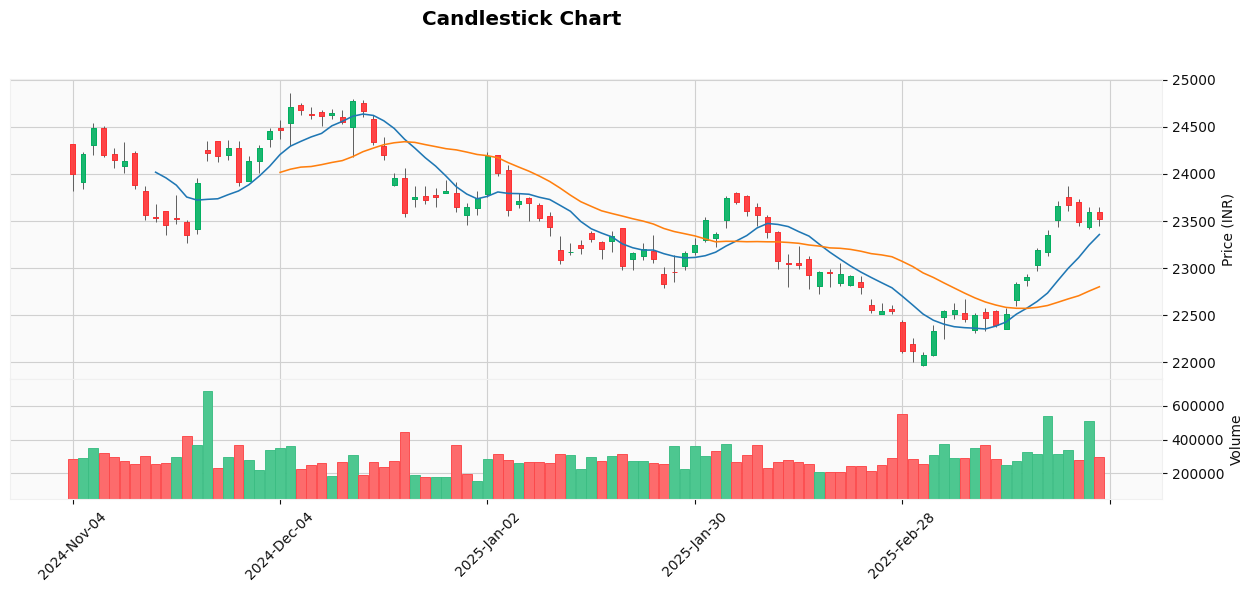

In [6]:
# Plotting Candlestick chart
mpf.plot(nifty[-100:], type="candle", style='yahoo', figsize=(16, 6), title="Candlestick Chart", ylabel="Price (INR)", mav=(9, 21), volume=True)

In [7]:
# Creating Bollinger Bands
nifty_bbands=nifty.ta.bbands(length=20, std=2, mamode="ema")

In [8]:
nifty_bbands

,BBL_20_2.0,BBM_20_2.0,BBU_20_2.0,BBB_20_2.0,BBP_20_2.0
Date,,,,,
2024-01-01,NaN,NaN,NaN,NaN,NaN
2024-01-02,NaN,NaN,NaN,NaN,NaN
2024-01-03,NaN,NaN,NaN,NaN,NaN
2024-01-04,NaN,NaN,NaN,NaN,NaN
2024-01-05,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...
2025-03-24,22059.3913,22848.2594,23637.1275,6.9053,1.0135
2025-03-25,22016.9618,22926.3919,23835.8220,7.9335,0.9081
2025-03-26,22005.1007,22979.7688,23954.4369,8.4828,0.7601


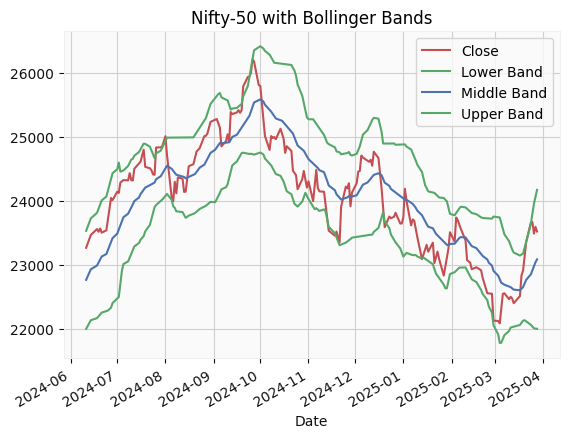

In [9]:
# Visualising Bollinger Bands Data
nifty["Close"][-200:].plot(color="r", label="Close")
nifty_bbands["BBL_20_2.0"][-200:].plot(color="g", label="Lower Band") #Lower Bollinger
nifty_bbands["BBM_20_2.0"][-200:].plot(color="b", label="Middle Band") # Middle Bollinger
nifty_bbands["BBU_20_2.0"][-200:].plot(color="g", label="Upper Band") # Upper Bollinger
plt.legend()
plt.title("Nifty-50 with Bollinger Bands")
plt.show()

In [10]:
# Calculating RSI
def RSI(df,n=14):
  df = df.copy()
  df["Change"]= df["Close"]-df["Close"].shift(1)
  df["Gain"]= np.where(df["Change"]>=0, df["Change"], 0)
  df["Loss"]=np.where((df["Change"])<0, df["Change"].abs(), 0)
  df["Average_Gain"]=df["Gain"].ewm(alpha=1/n, min_periods=n).mean()
  df["Average_Loss"]=df["Loss"].ewm(alpha=1/n, min_periods=n).mean()
  df["rs"] = df["Average_Gain"]/df["Average_Loss"]
  df["rsi"]= 100 - (100/(1+df["rs"]))
  return df

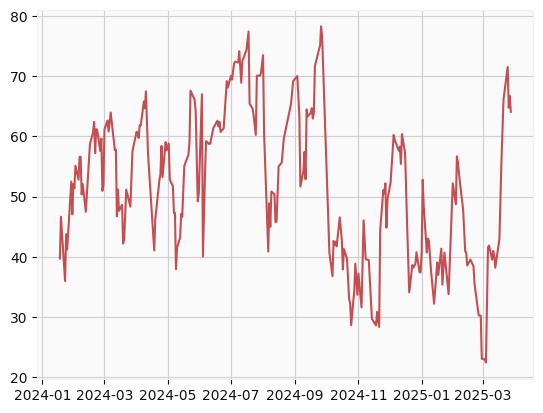

In [11]:
#Visualising RSI
df = RSI(nifty)
plt.plot (df["rsi"], color='r')

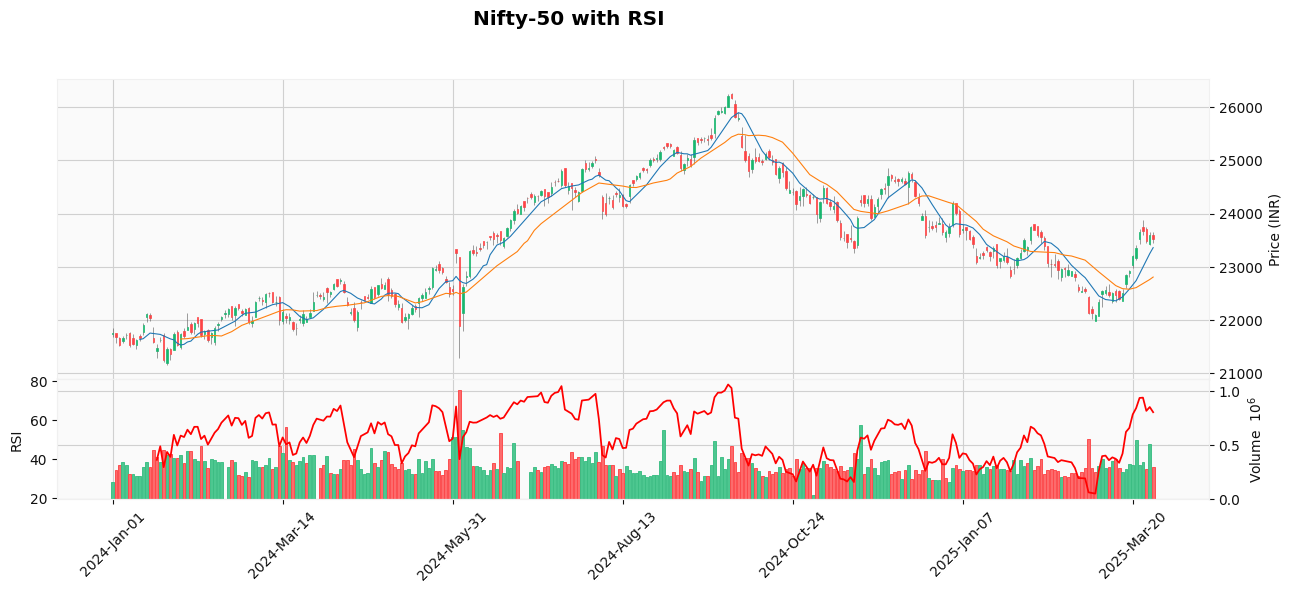

In [12]:
# Create the combined plot using mplfinance
apds = [mpf.make_addplot(df["rsi"], panel=1, color='red', secondary_y=True, ylabel='RSI')]
mpf.plot(df, type="candle", style='yahoo',figsize=(16, 6), title="Nifty-50 with RSI", ylabel="Price (INR)", mav=(9, 21), volume=True, addplot=apds)

2. Technical Analysis Trading Strategy

In [20]:
# Downloading 10-year data
ticker = "^NSEI"
start_date= "2020-01-01"
end_date = "2025-03-29"
df= yf.download(ticker, start=start_date, end=end_date, auto_adjust = False, multi_level_index=False)


# Create sma50, sma200 and then the "Golden Cross"
df["GC"] = df.ta.sma(50, append=True) > df.ta.sma(200, append=True)
df

[*********************100%***********************]  1 of 1 completed


,Adj Close,Close,High,Low,Open,Volume,SMA_50,SMA_200,GC
Date,,,,,,,,,
2020-01-01,12182.5000,12182.5000,12222.2002,12165.2998,12202.1504,304100,NaN,NaN,False
2020-01-02,12282.2002,12282.2002,12289.9004,12195.2500,12198.5498,407700,NaN,NaN,False
2020-01-03,12226.6504,12226.6504,12265.5996,12191.3496,12261.0996,428800,NaN,NaN,False
2020-01-06,11993.0498,11993.0498,12179.0996,11974.2002,12170.5996,396500,NaN,NaN,False
2020-01-07,12052.9502,12052.9502,12152.1504,12005.3496,12079.0996,447800,NaN,NaN,False
...,...,...,...,...,...,...,...,...,...
2025-03-24,23658.3496,23658.3496,23708.7500,23433.5000,23515.4004,311900,22972.0081,24069.7980,False
2025-03-25,23668.6504,23668.6504,23869.5996,23601.4004,23751.5000,338200,22976.7511,24075.0395,False
2025-03-26,23486.8496,23486.8496,23736.5000,23451.6992,23700.9492,278600,22984.7691,24078.3668,False


In [21]:
# Create boolean Signals(TS_Entries, TS_Exits) for vectorbt
golden = df.ta.tsignals(df.GC, asbool=True, append=True)
golden

,TS_Trends,TS_Trades,TS_Entries,TS_Exits
Date,,,,
2020-01-01,False,0,False,False
2020-01-02,False,0,False,False
2020-01-03,False,0,False,False
2020-01-06,False,0,False,False
2020-01-07,False,0,False,False
...,...,...,...,...
2025-03-24,False,0,False,False
2025-03-25,False,0,False,False
2025-03-26,False,0,False,False


In [22]:
# Sanity Check (Ensure data exists)
print(df)

            Adj Close      Close       High        Low       Open  Volume  \
Date                                                                        
2020-01-01 12182.5000 12182.5000 12222.2002 12165.2998 12202.1504  304100   
2020-01-02 12282.2002 12282.2002 12289.9004 12195.2500 12198.5498  407700   
2020-01-03 12226.6504 12226.6504 12265.5996 12191.3496 12261.0996  428800   
2020-01-06 11993.0498 11993.0498 12179.0996 11974.2002 12170.5996  396500   
2020-01-07 12052.9502 12052.9502 12152.1504 12005.3496 12079.0996  447800   
...               ...        ...        ...        ...        ...     ...   
2025-03-24 23658.3496 23658.3496 23708.7500 23433.5000 23515.4004  311900   
2025-03-25 23668.6504 23668.6504 23869.5996 23601.4004 23751.5000  338200   
2025-03-26 23486.8496 23486.8496 23736.5000 23451.6992 23700.9492  278600   
2025-03-27 23591.9492 23591.9492 23646.4492 23412.1992 23433.9492  510300   
2025-03-28 23519.3496 23519.3496 23649.1992 23450.1992 23600.4004  295400   

<ipython-input-23-1708d2555f4c>:16: UserWarning: This axis already has a converter set and is updating to a potentially incompatible converter
  plt.plot(nifty[nifty['Position'] == 1].index,
<ipython-input-23-1708d2555f4c>:26: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  if nifty['sma50'][-1] > nifty['sma200'][-1]:


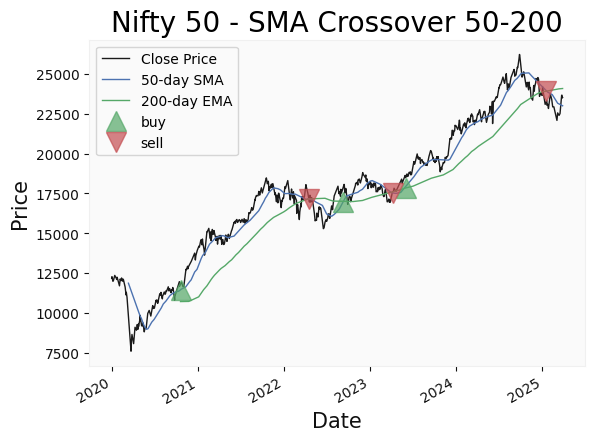

In [23]:
# Creating 50 SMA and 200 SMA buy-sell signals
nifty = pd.DataFrame()
nifty['Close'] = df['Close']
nifty['sma50'] = df.ta.sma(50, append=True)  # Calculate sma50
nifty['sma200'] = df.ta.sma(200, append=True)  # Calculate sma200
nifty['Signal'] = 0.0
nifty['Signal'] = np.where(nifty['sma50'] > nifty['sma200'], 1.0, 0.0)
nifty['Position'] = nifty['Signal'].diff()

# Plot close price, short-term and long-term moving averages
nifty['Close'].plot(color='k', lw=1, label='Close Price')
nifty['sma50'].plot(color='b', lw=1, label='50-day SMA')
nifty['sma200'].plot(color='g', lw=1, label='200-day EMA')

# Plot 'buy' signals
plt.plot(nifty[nifty['Position'] == 1].index,
         nifty['sma50'][nifty['Position'] == 1],
         '^', markersize=15, color='g', alpha=0.7, label='buy')

# Plot 'sell' signals
plt.plot(nifty[nifty['Position'] == -1].index,
         nifty['sma50'][nifty['Position'] == -1],
         'v', markersize=15, color='r', alpha=0.7, label='sell')

# 'Sell' on last day
if nifty['sma50'][-1] > nifty['sma200'][-1]:
    plt.plot(nifty.index[-1], nifty['sma50'][-1], marker=11, markersize=15, color='r', alpha=0.7, label='sell')

plt.ylabel('Price', fontsize=15)
plt.xlabel('Date', fontsize=15)
plt.title('Nifty 50 - SMA Crossover 50-200', fontsize=20)
plt.legend()
plt.grid()
plt.show()

In [ ]:
# Create the Signals Portfolio
import vectorbt as vbt
pf = vbt.Portfolio.from_signals(df.Close, entries=golden.TS_Entries, exits=golden.TS_Exits, freq="D", init_cash=100_000, fees=0.0025, slippage=0.0025)
pf.plot().show()

In [ ]:
# Print Portfolio Stats
print(pf.stats())

Start                         2020-03-30 00:00:00
End                           2025-03-28 00:00:00
Period                         1237 days 00:00:00
Start Value                           100000.0000
End Value                             143216.3815
Total Return [%]                          43.2164
Benchmark Return [%]                     184.0124
Max Gross Exposure [%]                   100.0000
Total Fees Paid                         1773.6087
Max Drawdown [%]                          14.1467
Max Drawdown Duration           526 days 00:00:00
Total Trades                                    3
Total Closed Trades                             3
Total Open Trades                               0
Open Trade PnL                             0.0000
Win Rate [%]                              66.6667
Best Trade [%]                            24.3176
Worst Trade [%]                           -2.1624
Avg Winning Trade [%]                     21.0806
Avg Losing Trade [%]                      -2.1624


In [ ]:
# Print Return Stats
print(pf.returns_stats())

Start                        2020-03-30 00:00:00
End                          2025-03-28 00:00:00
Period                        1237 days 00:00:00
Total Return [%]                         43.2164
Benchmark Return [%]                    184.0124
Annualized Return [%]                    11.1805
Annualized Volatility [%]                14.4381
Max Drawdown [%]                         14.1467
Max Drawdown Duration          526 days 00:00:00
Sharpe Ratio                              0.8065
Calmar Ratio                              0.7903
Omega Ratio                               1.1498
Sortino Ratio                             1.1344
Skew                                     -0.5326
Kurtosis                                  7.8788
Tail Ratio                                1.0221
Common Sense Ratio                        1.1364
Value at Risk                            -0.0116
Alpha                                    -0.0620
Beta                                      0.5519
dtype: object


In [ ]:
nifty = ohlcv_data["^NSEI"]

In [ ]:
def RSI_TA(DF,n=14):
  data = DF.copy()
  data["rsi"]=data.ta.rsi(length=n)
  return data

In [ ]:
# Back test using vectorbt
def RSI_TA_backtest(DF, n=14, a=30, b=70):
  # Calculate RSI
  data = DF.copy()
  data["rsi"]=data.ta.rsi(length=n)

  # Generate entry and exit signals
  entry_signal = data['rsi'] < a
  exit_signal = data['rsi'] > b

  # Use vectorbt to create and analyze the portfolio
  pf = vbt.Portfolio.from_signals(
      data['Close'],
      entries=entry_signal,
      exits=exit_signal,
      freq='D',
      init_cash=100000,
      fees=0.0025,
      slippage=0.0025
  )

  # Return portfolio statistics
  return pf

In [ ]:
# Call the backtest function
pf = RSI_TA_backtest(nifty)

# Print portfolio statistics
print(pf.stats())

Start                         2020-03-30 00:00:00
End                           2025-03-28 00:00:00
Period                         1237 days 00:00:00
Start Value                           100000.0000
End Value                             109831.0638
Total Return [%]                           9.8311
Benchmark Return [%]                     184.0124
Max Gross Exposure [%]                   100.0000
Total Fees Paid                         1628.8804
Max Drawdown [%]                          10.8431
Max Drawdown Duration            72 days 00:00:00
Total Trades                                    3
Total Closed Trades                             3
Total Open Trades                               0
Open Trade PnL                             0.0000
Win Rate [%]                              66.6667
Best Trade [%]                             7.4802
Worst Trade [%]                           -3.1420
Avg Winning Trade [%]                      6.5029
Avg Losing Trade [%]                      -3.1420


In [ ]:
# Visualise RSI backtest
for ticker in tickers:
  RSI_TA_backtest(ohlcv_data[ticker]).plot_value().show()

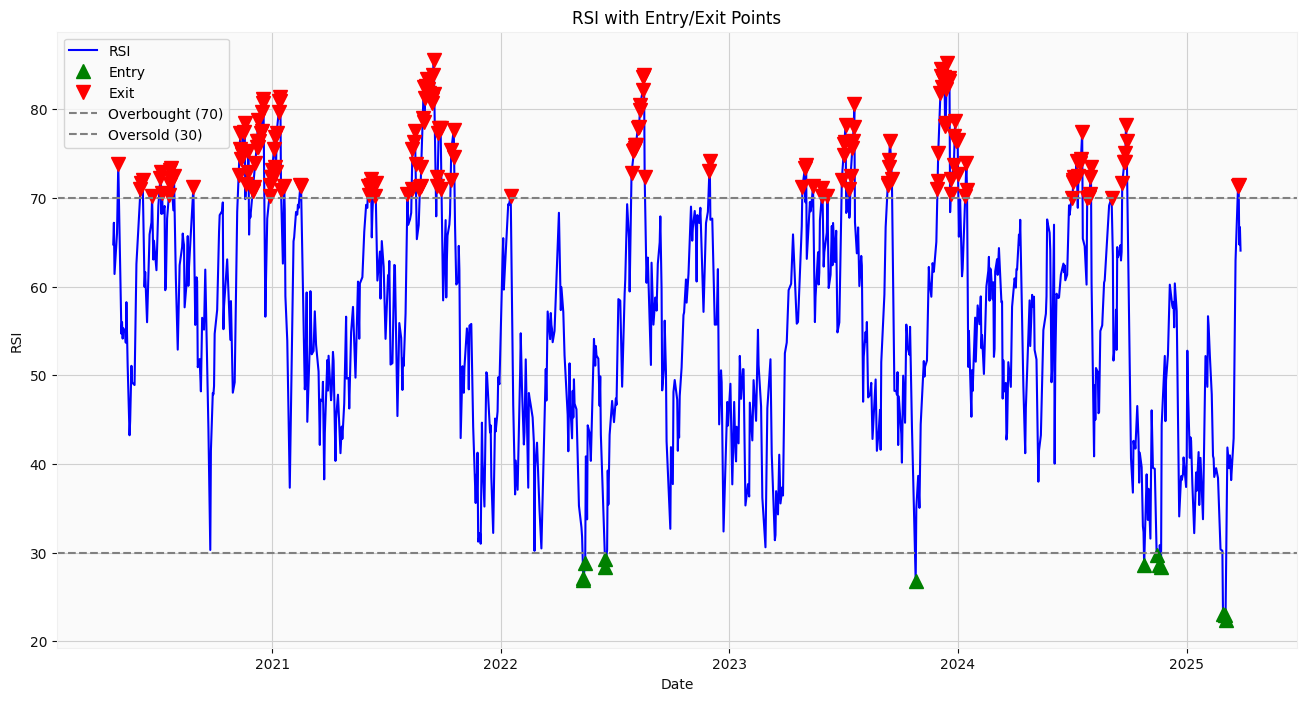

In [ ]:
def RSI(df, n=14):
    df = df.copy()

    # Accessing 'Close' column directly
    df["Change"] = df["Close"] - df["Close"].shift(1)
    df['Gain'] = np.where(df['Change'] >= 0, df["Change"], 0)
    df["Loss"] = np.where((df["Change"]) < 0, df["Change"].abs(), 0)
    df["Average_Gain"] = df["Gain"].ewm(alpha=1/n, min_periods=n).mean()
    df["Average_Loss"] = df["Loss"].ewm(alpha=1/n, min_periods=n).mean()
    df["rs"] = df["Average_Gain"]/df["Average_Loss"]
    df["rsi"] = 100 - (100/(1+df["rs"]))

    return df
import matplotlib.pyplot as plt

# Calculate RSI for the DataFrame
df = RSI(df)

# Find RSI entry and exit points
entry_points = df[df['rsi'] < 30].index
exit_points = df[df['rsi'] > 70].index


plt.figure(figsize=(16, 8))
plt.plot(df['rsi'], label='RSI', color='blue')

# Plot entry points as green up arrows
plt.plot(entry_points, df.loc[entry_points, 'rsi'], '^', markersize=10, color='green', label='Entry')

# Plot exit points as red down arrows
plt.plot(exit_points, df.loc[exit_points, 'rsi'], 'v', markersize=10, color='red', label='Exit')


plt.axhline(y=30, color='gray', linestyle='--', label='Overbought (70)')
plt.axhline(y=70, color='gray', linestyle='--', label='Oversold (30)')


plt.title('RSI with Entry/Exit Points')
plt.xlabel('Date')
plt.ylabel('RSI')
plt.legend()
plt.grid(True)
plt.show()

In [27]:
# Creating Bollinger Bands for NIfty-50 last 5 years
tickers = ['^NSEI']
ohlcv_data = {}

for ticker in tickers:
  ohlcv_data[ticker]=yf.download(ticker, period = '5y', interval = '1d', auto_adjust=False, multi_level_index=False)

nifty_bbands=nifty.ta.bbands(length=20, std=2, mamode="sma")
df = ohlcv_data['^NSEI'].copy()  # Replace 'MSFT' with your desired ticker if needed
df = ohlcv_data['^NSEI'].copy()  # Replace 'MSFT' with your desired ticker if needed
# Now you can calculate Bollinger Bands and proceed with the rest of the code
df['bbl'] = df.ta.bbands(length=20, std=2.0)['BBL_20_2.0']
df['bbm'] = df.ta.bbands(length=20, std=2.0)['BBM_20_2.0']
df['bbu'] = df.ta.bbands(length=20, std=2.0)['BBU_20_2.0']

[*********************100%***********************]  1 of 1 completed


<ipython-input-28-99f04404189a>:16: UserWarning: This axis already has a converter set and is updating to a potentially incompatible converter
  plt.plot(df[df['Position'] == 1].index,


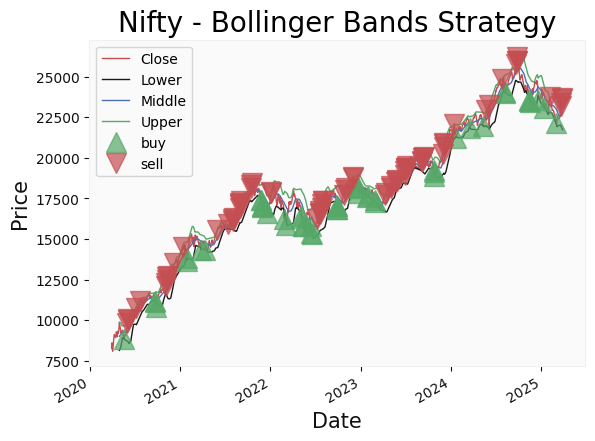

<Figure size 2000x1200 with 0 Axes>

<Figure size 2000x1200 with 0 Axes>

In [28]:
# Bollinger Bands buy-sell
df['Signal'] = 0.0
df['buy_signal'] = np.where(df['Close'] < df['bbl'], 1.0, 0.0)
df['sell_signal'] = np.where(df['Close'] > df['bbu'], -1.0, 0.0)
df['Signal'] = df['buy_signal'] + df['sell_signal']
df['Position'] = df['Signal']
df

# Plot close price, short-term and long-term moving averages
df['Close'].plot(color ='r', lw=1, label = 'Close')
df['bbl'].plot(color = 'k', lw = 1, label = 'Lower')
df['bbm'].plot(color = 'b', lw = 1, label = 'Middle')
df['bbu'].plot(color = 'g', lw = 1, label = 'Upper')

# Plot 'buy' signals
plt.plot(df[df['Position'] == 1].index,
         df['Close'][df['Position'] == 1],
         '^', markersize = 15, color = 'g', alpha = 0.7, label = 'buy')

# Plot 'sell' signals
plt.plot(df[df['Position'] == -1].index,
         df['Close'][df['Position'] == -1],
         'v', markersize = 15, color = 'r', alpha = 0.7, label = 'sell')

# Visualising the strategy
plt.ylabel('Price', fontsize = 15 )
plt.xlabel('Date', fontsize = 15 )
plt.title('Nifty - Bollinger Bands Strategy', fontsize = 20)
plt.legend();
plt.grid()
plt.show()

plt.figure(figsize=(20, 12)) # Increase figure size here

In [29]:
import vectorbt as vbt

def bollinger_bands_backtest(df, length=20, std=2):
    # Calculate Bollinger Bands
    # Access columns using f-string formatting with the correct float representation for std
    df['bbl'] = df.ta.bbands(length=length, std=std)[f'BBL_{length}_{std:.1f}']
    df['bbu'] = df.ta.bbands(length=length, std=std)[f'BBU_{length}_{std:.1f}']

    # Generate entry and exit signals
    entries = df['Close'] < df['bbl']
    exits = df['Close'] > df['bbu']

    # Use vectorbt to create and analyze the portfolio
    pf = vbt.Portfolio.from_signals(
        df['Close'],
        entries=entries,
        exits=exits,
        freq='D',
        init_cash=100000,
        fees=0.0025,
        slippage=0.0025
    )

    return pf

# Example usage:
pf = bollinger_bands_backtest(nifty)

# Print portfolio statistics
print(pf.stats())

# Plot portfolio value
pf.plot().show() # Changed from pf.plot_value().show()

# Plot other relevant metrics (e.g., returns, drawdowns) as needed
# Use vbt.plotting.plot_returns()
vbt.plotting.plot_returns(pf.returns()).show()
# Use vbt.plotting.plot_drawdowns() instead of pf.plot_drawdowns()
vbt.plotting.plot_drawdowns(pf.drawdowns()).show()

Start                         2020-01-01 00:00:00
End                           2025-03-28 00:00:00
Period                         1298 days 00:00:00
Start Value                           100000.0000
End Value                             121599.2577
Total Return [%]                          21.5993
Benchmark Return [%]                      93.0585
Max Gross Exposure [%]                   100.0000
Total Fees Paid                         6174.8427
Max Drawdown [%]                          37.6270
Max Drawdown Duration           582 days 00:00:00
Total Trades                                   12
Total Closed Trades                            12
Total Open Trades                               0
Open Trade PnL                             0.0000
Win Rate [%]                              66.6667
Best Trade [%]                            11.6824
Worst Trade [%]                          -16.9498
Avg Winning Trade [%]                      5.5977
Avg Losing Trade [%]                      -5.4876


AttributeError: module 'vectorbt.generic.plotting' has no attribute 'plot_returns'

In [31]:
# Print Return Stats
print(pf.returns_stats())


Start                        2020-01-01 00:00:00
End                          2025-03-28 00:00:00
Period                        1298 days 00:00:00
Total Return [%]                         21.5993
Benchmark Return [%]                     93.0585
Annualized Return [%]                     5.6532
Annualized Volatility [%]                19.1794
Max Drawdown [%]                         37.6270
Max Drawdown Duration          582 days 00:00:00
Sharpe Ratio                              0.3840
Calmar Ratio                              0.1502
Omega Ratio                               1.0965
Sortino Ratio                             0.5129
Skew                                     -1.8785
Kurtosis                                 37.5632
Tail Ratio                                1.0577
Common Sense Ratio                        1.1175
Value at Risk                            -0.0125
Alpha                                    -0.0756
Beta                                      0.7214
dtype: object


Total Return: -3.23%
Sharpe Ratio: -0.10


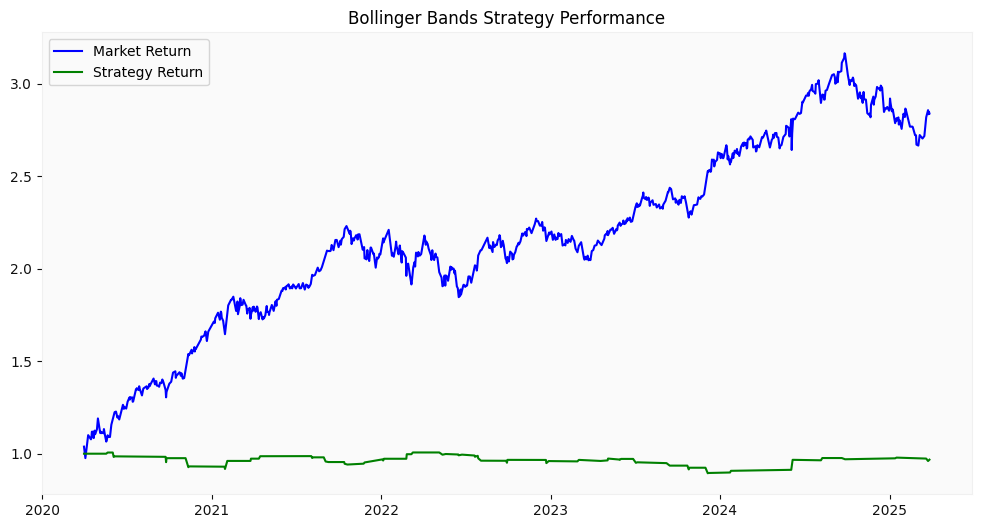

In [32]:
def backtest(df):
    # Calculate daily returns
    df['Daily_Return'] = df['Close'].pct_change()

    # Strategy returns
    df['Strategy_Return'] = df['Daily_Return'] * df['Position'].shift(1)

    # Calculate cumulative returns
    df['Cumulative_Market_Return'] = (1 + df['Daily_Return']).cumprod()
    df['Cumulative_Strategy_Return'] = (1 + df['Strategy_Return']).cumprod()

    # Performance metrics
    total_return = df['Cumulative_Strategy_Return'].iloc[-1] - 1
    sharpe_ratio = np.sqrt(252) * df['Strategy_Return'].mean() / df['Strategy_Return'].std()

    # Display performance
    print(f'Total Return: {total_return:.2%}')
    print(f'Sharpe Ratio: {sharpe_ratio:.2f}')

    # Plot results
    plt.figure(figsize=(12, 6))
    plt.plot(df['Cumulative_Market_Return'], label='Market Return', color='blue')
    plt.plot(df['Cumulative_Strategy_Return'], label='Strategy Return', color='green')
    plt.title('Bollinger Bands Strategy Performance')
    plt.legend()
    plt.grid()
    plt.show()

# Assuming df is already prepared as shown in your provided code
df = ohlcv_data['^NSEI'].copy()
df['bbl'] = df.ta.bbands(length=20, std=2.0)['BBL_20_2.0']
df['bbm'] = df.ta.bbands(length=20, std=2.0)['BBM_20_2.0']
df['bbu'] = df.ta.bbands(length=20, std=2.0)['BBU_20_2.0']

df['Signal'] = 0.0
df['buy_signal'] = np.where(df['Close'] < df['bbl'], 1.0, 0.0)
df['sell_signal'] = np.where(df['Close'] > df['bbu'], -1.0, 0.0)
df['Signal'] = df['buy_signal'] + df['sell_signal']
df['Position'] = df['Signal']

# Run backtest
backtest(df)